In [1]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"dimaneginsky","key":"6af17c2dd798b5129190b55aef5aea1c"}'}

In [2]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

**Exercise 1**: Duplicate Detection and Removal
Instructions
Objective: Identify and remove duplicate entries in the Titanic dataset.

Load the Titanic dataset.
Identify if there are any duplicate rows based on all columns.
Remove any duplicate rows found in the dataset.
Verify the removal of duplicates by checking the number of rows before and after the duplicate removal.

**Hint**: Use the duplicated() and drop_duplicates() functions in Pandas.


In [3]:
!kaggle competitions download -c titanic

100% 34.1k/34.1k [00:00<00:00, 87.3MB/s]



In [4]:
!unzip titanic.zip

Archive:  titanic.zip
  inflating: gender_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [7]:
import pandas as pd

In [9]:
titianic_train_df = pd.read_csv('/content/train.csv')
titianic_train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [13]:
titianic_train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Exercise 2**: Handling Missing Values
Instructions
Identify columns in the Titanic dataset with missing values.
Explore different strategies for handling missing data, such as removal, imputation, and filling with a constant value.
Apply each strategy to different columns based on the nature of the data.
Hint: Review methods like dropna(), fillna(), and SimpleImputer from scikit-learn.

In [12]:
print(titianic_train_df.duplicated().sum())
# there were nu duplicate rows in the train data of the data set -> sum is 0

0


In [14]:
cleaned_titanic_df = titianic_train_df.drop_duplicates()
print(cleaned_titanic_df.duplicated().sum())

0


In [15]:
cleaned_titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


**Exercise 3**: Feature Engineering
Instructions

Create new features, such as Family Size from SibSp and Parch, and Title extracted from the Name column.
Convert categorical variables into numerical form using techniques like one-hot encoding or label encoding.
You will encode new categorical features (like Title) here, but do not scale numerical features yet — that will come after outlier handling.
Hint: Utilize Pandas for data manipulation and scikit-learn’s preprocessing module for encoding.

In [17]:
# another look at the data and the columns:
cleaned_titanic_df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


**From Kaggle documentation**: https://www.kaggle.com/competitions/titanic/data

**sibsp**: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

**parch**: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

In [40]:
print(cleaned_titanic_df[['SibSp','Parch']].describe())
# number of siblings or spouses, values overview:
SibSp_vals = list(cleaned_titanic_df['SibSp'])
SibSp_vals.sort()
print(set(SibSp_vals))
# Parch - parent/children, values overview:
Parch_vals = list(cleaned_titanic_df['Parch'])
Parch_vals.sort()
print(set(Parch_vals))

            SibSp       Parch
count  891.000000  891.000000
mean     0.523008    0.381594
std      1.102743    0.806057
min      0.000000    0.000000
25%      0.000000    0.000000
50%      0.000000    0.000000
75%      1.000000    0.000000
max      8.000000    6.000000
{0, 1, 2, 3, 4, 5, 8}
{0, 1, 2, 3, 4, 5, 6}


In [42]:
# Creating a new feature family_size from the sum of parents/children and sibling/spouses family members
cleaned_titanic_df['family_size'] = cleaned_titanic_df['SibSp'] + cleaned_titanic_df['Parch']

In [54]:
# reviewing the Name col values to understand what Titles there are:
print(cleaned_titanic_df['Name'][0:60])

0                               Braund, Mr. Owen Harris
1     Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                Heikkinen, Miss. Laina
3          Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                              Allen, Mr. William Henry
5                                      Moran, Mr. James
6                               McCarthy, Mr. Timothy J
7                        Palsson, Master. Gosta Leonard
8     Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                   Nasser, Mrs. Nicholas (Adele Achem)
10                      Sandstrom, Miss. Marguerite Rut
11                             Bonnell, Miss. Elizabeth
12                       Saundercock, Mr. William Henry
13                          Andersson, Mr. Anders Johan
14                 Vestrom, Miss. Hulda Amanda Adolfina
15                     Hewlett, Mrs. (Mary D Kingcome) 
16                                 Rice, Master. Eugene
17                         Williams, Mr. Charles

In [62]:
# playing around with name column to extract titles:
cleaned_titanic_df['Name'][58].split(", ")[1].split(".")[0]

'Miss'

In [64]:
# playing around with name column to extract titles:
cleaned_titanic_df['Name'][58].find(', ')

4

In [70]:
# reviewing unique title values, whether it becomes an 'interesting' feature:
set(list([(name.split(", ")[1].split(".")[0]) for name in cleaned_titanic_df['Name']]))

{'Capt',
 'Col',
 'Don',
 'Dr',
 'Jonkheer',
 'Lady',
 'Major',
 'Master',
 'Miss',
 'Mlle',
 'Mme',
 'Mr',
 'Mrs',
 'Ms',
 'Rev',
 'Sir',
 'the Countess'}

In [67]:
[(ind, name.split(", ")[1].split(".")[0]) for ind,name in enumerate(cleaned_titanic_df['Name'])]

[(0, 'Mr'),
 (1, 'Mrs'),
 (2, 'Miss'),
 (3, 'Mrs'),
 (4, 'Mr'),
 (5, 'Mr'),
 (6, 'Mr'),
 (7, 'Master'),
 (8, 'Mrs'),
 (9, 'Mrs'),
 (10, 'Miss'),
 (11, 'Miss'),
 (12, 'Mr'),
 (13, 'Mr'),
 (14, 'Miss'),
 (15, 'Mrs'),
 (16, 'Master'),
 (17, 'Mr'),
 (18, 'Mrs'),
 (19, 'Mrs'),
 (20, 'Mr'),
 (21, 'Mr'),
 (22, 'Miss'),
 (23, 'Mr'),
 (24, 'Miss'),
 (25, 'Mrs'),
 (26, 'Mr'),
 (27, 'Mr'),
 (28, 'Miss'),
 (29, 'Mr'),
 (30, 'Don'),
 (31, 'Mrs'),
 (32, 'Miss'),
 (33, 'Mr'),
 (34, 'Mr'),
 (35, 'Mr'),
 (36, 'Mr'),
 (37, 'Mr'),
 (38, 'Miss'),
 (39, 'Miss'),
 (40, 'Mrs'),
 (41, 'Mrs'),
 (42, 'Mr'),
 (43, 'Miss'),
 (44, 'Miss'),
 (45, 'Mr'),
 (46, 'Mr'),
 (47, 'Miss'),
 (48, 'Mr'),
 (49, 'Mrs'),
 (50, 'Master'),
 (51, 'Mr'),
 (52, 'Mrs'),
 (53, 'Mrs'),
 (54, 'Mr'),
 (55, 'Mr'),
 (56, 'Miss'),
 (57, 'Mr'),
 (58, 'Miss'),
 (59, 'Master'),
 (60, 'Mr'),
 (61, 'Miss'),
 (62, 'Mr'),
 (63, 'Master'),
 (64, 'Mr'),
 (65, 'Master'),
 (66, 'Mrs'),
 (67, 'Mr'),
 (68, 'Miss'),
 (69, 'Mr'),
 (70, 'Mr'),
 (71, 'Miss')

In [72]:
#adding & reviewing the resulting new feature 'title:
cleaned_titanic_df['title']=[(name.split(", ")[1].split(".")[0]) for name in cleaned_titanic_df['Name']]
cleaned_titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,family_size,title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,1,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,1,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,0,Mr


In [74]:
# one-hot encoding for variable'sex' -> binary for male and binary for female:
cleaned_titanic_df = pd.get_dummies(cleaned_titanic_df, columns=['Sex'])

KeyError: "None of [Index(['Sex'], dtype='object')] are in the [columns]"

In [84]:
# from Kaggle documentation: Port of Embarkation	C = Cherbourg, Q = Queenstown, S = Southampton
# Reviewing the data first, before applying numeric labeling:
print(cleaned_titanic_df['Embarked'].describe())
print(f"unique values for 'Embarked' features: {set(cleaned_titanic_df['Embarked'].unique())}\n")

print(f"unique counts: {cleaned_titanic_df['Embarked'].value_counts()}\n")
print(f"NaN counts: {cleaned_titanic_df['Embarked'].isna().sum()}\n")
print(f"counts by value: {cleaned_titanic_df['Embarked'].groupby(cleaned_titanic_df['Embarked']).count()}")


count     889
unique      3
top         S
freq      644
Name: Embarked, dtype: object
unique values for 'Embarked' features: {'Q', 'C', 'S', nan}

unique counts: Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

NaN counts: 2

counts by value: Embarked
C    168
Q     77
S    644
Name: Embarked, dtype: int64


In [78]:
# label encoding
cleaned_titanic_df['Embarked2'] = cleaned_titanic_df['Embarked'].astype('category')
cleaned_titanic_df['Embarked_cat'] = cleaned_titanic_df['Embarked2'].cat.codes

In [79]:
cleaned_titanic_df.head(3)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,family_size,title,Sex_female,Sex_male,Embarked2,Embarked_cat
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,S,1,Mr,False,True,S,2
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,C,1,Mrs,True,False,C,0
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,Miss,True,False,S,2


In [91]:
# reviewing the encoding:
list(cleaned_titanic_df['Embarked_cat'].groupby(cleaned_titanic_df['Embarked2'],observed=False))

[('C',
  1      0
  9      0
  19     0
  26     0
  30     0
        ..
  866    0
  874    0
  875    0
  879    0
  889    0
  Name: Embarked_cat, Length: 168, dtype: int8),
 ('Q',
  5      1
  16     1
  22     1
  28     1
  32     1
        ..
  790    1
  825    1
  828    1
  885    1
  890    1
  Name: Embarked_cat, Length: 77, dtype: int8),
 ('S',
  0      2
  2      2
  3      2
  4      2
  6      2
        ..
  883    2
  884    2
  886    2
  887    2
  888    2
  Name: Embarked_cat, Length: 644, dtype: int8)]

**Exercise 4**: Outlier Detection and Handling
Goal: Detect and cap or transform outliers in columns like Fare and Age.

1. Visualize distributions using boxplots or histograms to identify potential outliers.
2. Use IQR or Z-score methods to detect them.
3. Handle outliers with: Quantile capping (e.g. 0.98),
Log transformation, Row removal

4. Compare the dataset before and after treatment.

📌 Note: Small differences between 0.98 and 0.99 quantiles are normal when extreme values are rare or far apart. Use df.quantile() to explore and choose thresholds empirically, backed by visualization.

In [92]:
cleaned_titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   PassengerId   891 non-null    int64   
 1   Survived      891 non-null    int64   
 2   Pclass        891 non-null    int64   
 3   Name          891 non-null    object  
 4   Age           714 non-null    float64 
 5   SibSp         891 non-null    int64   
 6   Parch         891 non-null    int64   
 7   Ticket        891 non-null    object  
 8   Fare          891 non-null    float64 
 9   Cabin         204 non-null    object  
 10  Embarked      889 non-null    object  
 11  family_size   891 non-null    int64   
 12  title         891 non-null    object  
 13  Sex_female    891 non-null    bool    
 14  Sex_male      891 non-null    bool    
 15  Embarked2     889 non-null    category
 16  Embarked_cat  891 non-null    int8    
dtypes: bool(2), category(1), float64(2), int64(6), int8(1)

In [95]:
cleaned_titanic_df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0
Cabin,687


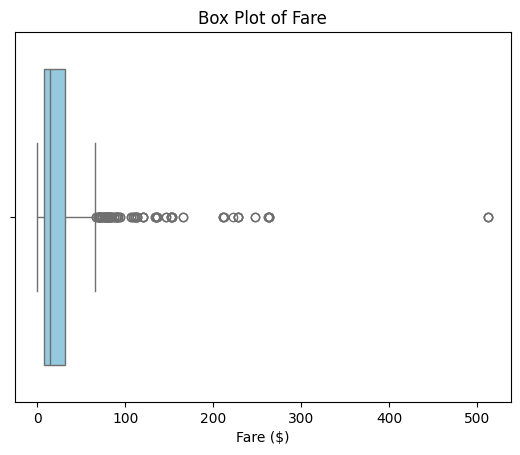

In [114]:
import seaborn as sns

# box plot for Fares

sns.boxplot(x=cleaned_titanic_df['Fare'].dropna(), color='skyblue')
plt.title('Box Plot of Fare')
plt.xlabel('Fare ($)')
plt.show()

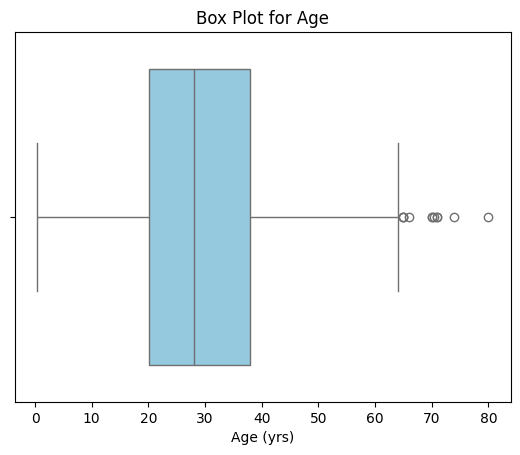

In [115]:
# box plot for Fares

sns.boxplot(x = cleaned_titanic_df['Age'].dropna(), color='skyblue')
plt.title('Box Plot for Age')
plt.xlabel('Age (yrs)')
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.boxplot(df['Fare'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='lightblue'))
plt.title('Box Plot of Fare – Titanic')
plt.xlabel('Fare in $')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

In [103]:
# Checking Age for outliers, among the non-nan values
age_Q25 = cleaned_titanic_df['Age'].quantile(0.25)
age_Q75= cleaned_titanic_df['Age'].quantile(0.75)
IQR = age_Q75 - age_Q25
print(f"IQR-based outlier LB,UB: {float(age_Q25 - 1.5*IQR), float(age_Q75 + 1.5*IQR)}")

print(f"min: {cleaned_titanic_df['Age'].min()}, max: {cleaned_titanic_df['Age'].max()}")

print(f"99% quantile: {cleaned_titanic_df['Age'].quantile(0.99)}")
print(f"97.5% quantile: {cleaned_titanic_df['Age'].quantile(0.975)}")


IQR-based outlier LB,UB: (-6.6875, 64.8125)
min: 0.42, max: 80.0
99% quantile: 65.87
99% quantile: 62.0


In [107]:
# 65 seems to be a good choice to cap the age outliers
# filter for Age outliers and cap them:
cleaned_titanic_df['age_capped'] = cleaned_titanic_df['Age'].apply(lambda x: 65 if x > 65 else x)
# double check what happened to Nan values (as we have not dropped them yet:
cleaned_titanic_df[cleaned_titanic_df['Age'].isnull()][['Age','age_capped']] # -> remained NaN OK!


,Age,age_capped
5,NaN,NaN
17,NaN,NaN
19,NaN,NaN
26,NaN,NaN
28,NaN,NaN
...,...,...
859,NaN,NaN
863,NaN,NaN
868,NaN,NaN
878,NaN,NaN


In [111]:
# # Checking Fare for outliers, among the non-nan values
Fare_Q25 = cleaned_titanic_df['Fare'].quantile(0.25)
Fare_Q75= cleaned_titanic_df['Fare'].quantile(0.75)
IQR_Fare = Fare_Q75 - Fare_Q25
print(f"IQR border: {Fare_Q25} - {Fare_Q75}")
print(f"IQR-based outlier LB,UB: {float(Fare_Q25 - 1.5*IQR_Fare), float(Fare_Q75 + 1.5*IQR_Fare)}")

print(f"min: {cleaned_titanic_df['Fare'].min()}, max: {cleaned_titanic_df['Fare'].max()}")

print(f"99% quantile: {cleaned_titanic_df['Fare'].quantile(0.99)}")
print(f"97.5% quantile: {cleaned_titanic_df['Fare'].quantile(0.975)}")

IQR border: 7.9104 - 31.0
IQR-based outlier LB,UB: (-26.724, 65.6344)
min: 0.0, max: 512.3292
99% quantile: 249.00622000000035
97.5% quantile: 153.4625


In [112]:
# 97.5% seems sufficient value to cap Fare putliers with
# filter for Age outliers and cap them:
cleaned_titanic_df['fare_capped'] = cleaned_titanic_df['Fare'].apply(lambda x: cleaned_titanic_df['Fare'].quantile(0.975) if x > 65 else x)

In [116]:
# Comparing data - original vs capped:
cleaned_titanic_df[['Age','age_capped','Fare','fare_capped']].describe()

,Age,age_capped,Fare,fare_capped
count,714.000000,714.000000,891.000000,891.000000
mean,29.699118,29.625588,32.204208,35.481224
std,14.526497,14.323792,49.693429,47.393279
min,0.420000,0.420000,0.000000,0.000000
25%,20.125000,20.125000,7.910400,7.910400
50%,28.000000,28.000000,14.454200,14.454200
75%,38.000000,38.000000,31.000000,31.000000
max,80.000000,65.000000,512.329200,153.462500


In [117]:
# checking quantiles:
cleaned_titanic_df[['Age','age_capped','Fare','fare_capped']].quantile(0.99)

,0.99
Age,65.87000
age_capped,65.00000
Fare,249.00622
fare_capped,153.46250


In [125]:
# checking how the average 99%-percentile outliers changed after capping:
for col in ['Age','age_capped','Fare','fare_capped']:
  print(f"outlier-average for {col}: {cleaned_titanic_df[cleaned_titanic_df[col] >= cleaned_titanic_df[col].quantile(0.99)][col].mean()}")

outlier-average for Age: 71.5625
outlier-average for age_capped: 65.0
outlier-average for Fare: 345.9708444444445
outlier-average for fare_capped: 153.46250000000006


**Exercise 5**: Data Standardization and Normalization
Goal: Scale numerical features to prepare for modeling.

Use StandardScaler (mean = 0, std = 1) for normally distributed features.
Use MinMaxScaler (range [0, 1]) for features that are skewed or bounded.
📌 Important: Perform this step after outlier treatment to avoid distortion caused by extreme values.

In [126]:
# checking one more time our data frame before removing NaN and including only useful reeingineered features:
cleaned_titanic_df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,family_size,Embarked_cat,age_capped,fare_capped
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000,891.000000,891.000000,714.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208,0.904602,1.529742,29.625588,35.481224
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429,1.613459,0.800254,14.323792,47.393279
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000,0.000000,-1.000000,0.420000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400,0.000000,1.000000,20.125000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200,0.000000,2.000000,28.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000,1.000000,2.000000,38.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200,10.000000,2.000000,65.000000,153.462500


In [131]:
cleaned_titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   PassengerId             891 non-null    int64   
 1   Survived                891 non-null    int64   
 2   Pclass                  891 non-null    int64   
 3   Name                    891 non-null    object  
 4   Age                     714 non-null    float64 
 5   SibSp                   891 non-null    int64   
 6   Parch                   891 non-null    int64   
 7   Ticket                  891 non-null    object  
 8   Fare                    891 non-null    float64 
 9   Cabin                   204 non-null    object  
 10  Embarked                889 non-null    object  
 11  family_size             891 non-null    int64   
 12  title                   891 non-null    object  
 13  Sex_female              891 non-null    bool    
 14  Sex_male                89

**Exercise 5**: Data Standardization and Normalization
Goal: Scale numerical features to prepare for modeling.

Use StandardScaler (mean = 0, std = 1) for normally distributed features.
Use MinMaxScaler (range [0, 1]) for features that are skewed or bounded.
📌 Important: Perform this step after outlier treatment to avoid distortion caused by extreme values.

In [129]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [130]:
# normalizing capped fare and age columns:
cleaned_titanic_df['fare_capped_normalized'] = scaler.fit_transform(cleaned_titanic_df[['fare_capped']])

In [137]:
cleaned_titanic_df['age_capped_normalized'] = scaler.fit_transform(cleaned_titanic_df[['age_capped']])

In [153]:
# to drop nan because of age and cabin, remove cabin column fully - no obvious use and only 204 values
final_df = cleaned_titanic_df.copy()
final_df = final_df.drop(['Cabin', 'Ticket'], axis=1)

# drop remaining NaNs, should be the rwos with Age NaN and 2 with Embarked na:
final_df = final_df[final_df['Age'].isnull() == False]
final_df = final_df[final_df['Embarked'].isnull() == False]
print(final_df.info())
print(final_df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 0 to 890
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   PassengerId             712 non-null    int64   
 1   Survived                712 non-null    int64   
 2   Pclass                  712 non-null    int64   
 3   Name                    712 non-null    object  
 4   Age                     712 non-null    float64 
 5   SibSp                   712 non-null    int64   
 6   Parch                   712 non-null    int64   
 7   Fare                    712 non-null    float64 
 8   Embarked                712 non-null    object  
 9   family_size             712 non-null    int64   
 10  title                   712 non-null    object  
 11  Sex_female              712 non-null    bool    
 12  Sex_male                712 non-null    bool    
 13  Embarked2               712 non-null    category
 14  Embarked_cat            712 non

In [154]:
# now keeping only the relevant for analysis column: normalized/encoded ones instead of the originals:
final_df = final_df [['PassengerId','Survived','Pclass','title','family_size','Sex_female','Sex_male','Embarked_cat','age_capped_normalized','fare_capped_normalized']]
final_df.head(3)

,PassengerId,Survived,Pclass,title,family_size,Sex_female,Sex_male,Embarked_cat,age_capped_normalized,fare_capped_normalized
0,1,0,3,Mr,1,False,True,2,-0.532745,-0.596014
1,2,1,1,Mrs,1,True,False,0,0.585060,2.490808
2,3,1,3,Miss,0,True,False,2,-0.253294,-0.581764


**Exercise 6**: Feature Encoding
Goal: Finalize categorical variable encoding.

1. Identify remaining categorical columns (e.g. Sex, Embarked, Title).
2. Apply:
One-Hot Encoding for nominal variables.
Label Encoding if any ordinal variables remain.
3. Merge encoded columns back into the main dataset.

📌 Reminder: Encoding comes after handling missing values and outliers, but before scaling (if applicable).


--> Done in Exercise 3

**Exercise 7**: Data Transformation for Age Feature
Goal: Create and encode age groups.

Use pd.cut() to create bins for life stages (e.g. child, teen, adult, senior).
Apply one-hot encoding using pd.get_dummies().
📌 Example: You might define bins like [0, 12, 18, 60, 100] and label them accordingly.

In [157]:
age_groups = ['child', 'teen', 'adult', 'senior']
# cleaned_titanic_df['age_group'] =
cleaned_titanic_df['age_'] = pd.DataFrame(pd.cut(cleaned_titanic_df['Age'], bins=[0, 12, 18, 60, 100], labels=age_groups))
cleaned_titanic_df.head(3)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,...,Embarked_cat,age_capped,fare_capped,fare_capped_normalized,age_capped_normalized,age_labels_child,age_labels_teen,age_labels_adult,age_labels_senior,age_
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,...,2,22.0,7.2500,-0.596014,-0.532745,False,False,True,False,adult
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,...,0,38.0,153.4625,2.490808,0.585060,False,False,True,False,adult
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,...,2,26.0,7.9250,-0.581764,-0.253294,False,False,True,False,adult


In [158]:
cleaned_titanic_df = pd.get_dummies(cleaned_titanic_df, columns=['age_'])
cleaned_titanic_df.head(3)

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,...,fare_capped_normalized,age_capped_normalized,age_labels_child,age_labels_teen,age_labels_adult,age_labels_senior,age__child,age__teen,age__adult,age__senior
0,1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,...,-0.596014,-0.532745,False,False,True,False,False,False,True,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,...,2.490808,0.585060,False,False,True,False,False,False,True,False
2,3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,...,-0.581764,-0.253294,False,False,True,False,False,False,True,False


In [160]:
final_df = pd.merge(final_df, cleaned_titanic_df[['PassengerId','age__child','age__teen','age__adult','age__senior']], on='PassengerId', how='left')
final_df.head()

,PassengerId,Survived,Pclass,title,family_size,Sex_female,Sex_male,Embarked_cat,age_capped_normalized,fare_capped_normalized,age__child,age__teen,age__adult,age__senior
0,1,0,3,Mr,1,False,True,2,-0.532745,-0.596014,False,False,True,False
1,2,1,1,Mrs,1,True,False,0,0.585060,2.490808,False,False,True,False
2,3,1,3,Miss,0,True,False,2,-0.253294,-0.581764,False,False,True,False
3,4,1,1,Mrs,1,True,False,2,0.375472,0.371966,False,False,True,False
4,5,0,3,Mr,0,False,True,2,0.375472,-0.579125,False,False,True,False
